# 01 - Audio Basics for Speech AI Engineering

Welcome to **Phase 1** of the Hindi Speech Processing Pipeline!
In this notebook, we explore the fundamental representations of audio that underpin all modern Automatic Speech Recognition (ASR) and Text-to-Speech (TTS) models:

1. **The Raw Waveform**: How continuous sound vibrations become discrete numbers in time.
2. **Sampling Rate & Nyquist Theorem**: Why 16 kHz is the standard for speech AI.
3. **Resampling**: How to reliably convert between sampling rates without aliasing artifacts.
4. **Short-Time Fourier Transform (STFT)**: Moving from the time domain to the frequency domain using overlapping analysis frames.
5. **The Mel Scale & Log-Mel Spectrogram**: How human auditory perception shapes the 80-channel feature representation consumed by **Whisper**.


### 1. Setup & Imports
We import our core audio processing libraries:
- `soundfile`: Fast, uncompressed audio reading/writing.
- `librosa`: The standard Python library for audio and music signal processing.
- `matplotlib`: Clean, publication-quality plotting of waveforms and spectrograms.
- `src.data`: Our custom loader built in Phase 0 for loading Google FLEURS Hindi with robust bytes decoding.


In [1]:
import io
import sys
import os
import numpy as np
import soundfile as sf
import librosa
import librosa.display
import matplotlib.pyplot as plt

# Ensure local modules can be resolved
sys.path.append(os.path.abspath(".."))
from src.data import load_fleurs_hindi, decode_audio_sample

# Configure high-DPI clean plotting style
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.size"] = 10


C:\Users\dkhan\Desktop\IIIT Hyderabad Speech Processing Lab\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 2. Loading a Hindi Audio Sample
We load a validation clip from Google FLEURS (`hi_in`).
Because HuggingFace `datasets>=4.0` defaults to `torchcodec` on some systems, our custom loader loads raw bytes (`Audio(decode=False)`) and decodes them with `soundfile` and `librosa`.


In [2]:
# Load the first validation example from Google FLEURS hi_in
val_dataset = load_fleurs_hindi(split="validation[:1]", decode_audio=False)
sample = val_dataset[0]

# Decode the raw audio bytes into a float32 NumPy array at 16,000 Hz
audio_array, sample_rate = decode_audio_sample(sample["audio"], target_sr=16000)

print("=== Audio Sample Metadata ===")
print(f"Sample ID:            {sample['id']}")
print(f"Hindi Transcription:  {sample['transcription']}")
print(f"Speaker Gender:       {'Female' if sample.get('gender') == 0 else 'Male'}")
print(f"Sampling Rate:        {sample_rate:,} Hz")
print(f"Total Samples:        {len(audio_array):,}")
print(f"Duration:             {len(audio_array) / sample_rate:.2f} seconds")
print(f"Min / Max Amplitude:  {audio_array.min():.4f} / {audio_array.max():.4f}")
print(f"NumPy Dtype:          {audio_array.dtype}")


=== Audio Sample Metadata ===
Sample ID:            1602
Hindi Transcription:  मेजरकेन खाना भूमध्य सागर में समान क्षेत्रों की तरह रोटी सब्जियों और मांस विशेष रूप से सूअर का मांस पर आधारित है और जैतून के तेल का उपयोग करता है।
Speaker Gender:       Male
Sampling Rate:        16,000 Hz
Total Samples:        195,840
Duration:             12.24 seconds
Min / Max Amplitude:  -0.0717 / 0.1093
NumPy Dtype:          float32


### 3. Audio Representation in the Time Domain (The Waveform)

#### What is Sampling Rate?
Sound is a continuous mechanical pressure wave traveling through air. To store it digitally, a microphone measures the air pressure amplitude at regular discrete time intervals.
- **Sampling Rate ($f_s$ or SR)**: The number of amplitude snapshots captured per second, measured in **Hertz (Hz)**.
- **Duration**: $\text{Duration (seconds)} = \frac{\text{Total Samples}}{f_s}$.

#### The Nyquist-Shannon Sampling Theorem
To faithfully capture a frequency $f_{\text{max}}$ without distortion, the sampling rate must be at least twice that frequency:
$$f_s \ge 2 \cdot f_{\text{max}} \quad \Longleftrightarrow \quad f_{\text{Nyquist}} = \frac{f_s}{2}$$

- Human hearing ranges from **20 Hz to 20,000 Hz**.
- For human speech, the most critical phonetic information (vowels and consonants) lies between **300 Hz and 7,500 Hz**:
  - Vowel formants: $250\text{ Hz} - 3,000\text{ Hz}$.
  - Fricatives ("s", "sh", "f"): up to $7,000\text{ Hz} - 8,000\text{ Hz}$.
- Therefore, a sampling rate of **16,000 Hz (16 kHz)** has a Nyquist cutoff of **8,000 Hz (8 kHz)**, preserving 100% of intelligibility while cutting storage and compute by two-thirds compared to 44.1 kHz music audio! This is why Whisper, Wav2Vec2, and MMS all standardize on 16 kHz.

Let's plot the time-domain waveform below.


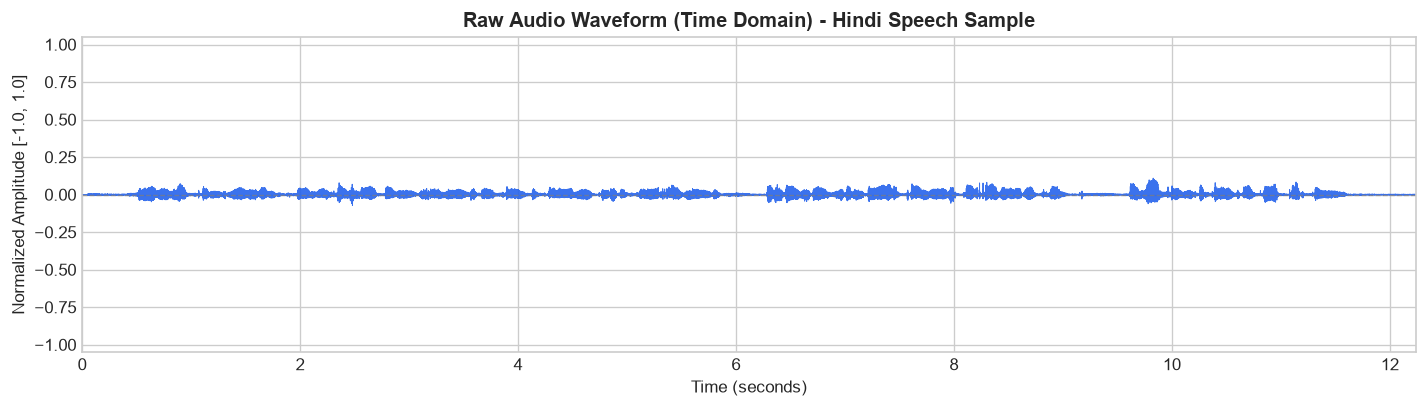

In [3]:
# Compute the time vector in seconds
time_axis = np.linspace(0, len(audio_array) / sample_rate, num=len(audio_array))

# Create the waveform plot
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(time_axis, audio_array, color="#2563EB", linewidth=0.6, alpha=0.9)
ax.set_title("Raw Audio Waveform (Time Domain) - Hindi Speech Sample", fontsize=12, fontweight="bold")
ax.set_xlabel("Time (seconds)")
ax.set_ylabel("Normalized Amplitude [-1.0, 1.0]")
ax.set_xlim(0, time_axis[-1])
ax.set_ylim(-1.05, 1.05)
ax.axhline(0, color="gray", linestyle="--", linewidth=0.8, alpha=0.7)
plt.tight_layout()
plt.show()


### 4. Audio Resampling: Converting Between Sampling Rates

What happens when an audio file arrives at 8 kHz (e.g. traditional phone calls) or 48 kHz (high-end studio microphones)?
Models like Whisper **require exactly 16 kHz**. Passing 8 kHz or 48 kHz without resampling will completely corrupt the acoustic features:
- If 48 kHz audio is fed into a 16 kHz model without resampling, the model perceives speech played at 3x slow motion!
- If 8 kHz audio is fed without resampling, the model perceives speech at 2x fast forward!

#### Anti-Aliasing & Polyphase Filtering
Resampling is **not** simply deleting every $N$-th sample (naive decimation). Decimating without filtering causes high frequencies above the new Nyquist limit to fold over into low frequencies—an irreversible distortion called **aliasing**.
`librosa.resample` applies a sinc-interpolated polyphase anti-aliasing low-pass filter to cleanly remove frequencies above the target Nyquist boundary before resampling.


Original 16 kHz sample count:       195,840
Downsampled 8 kHz sample count:     97,920
Resampled back to 16 kHz count:     195,840


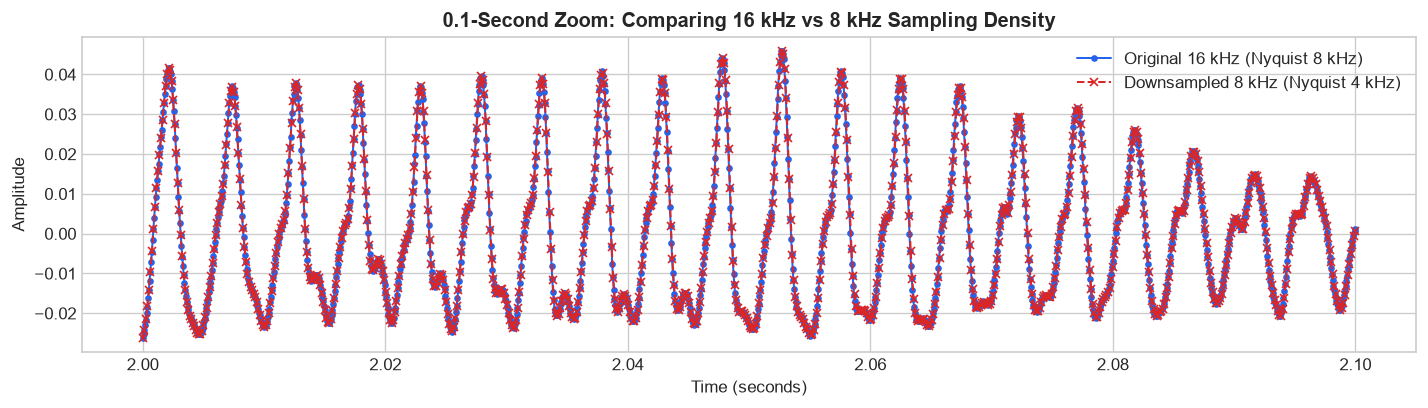

In [4]:
# 1. Downsample from 16 kHz to 8 kHz (telephony rate)
audio_8k = librosa.resample(audio_array, orig_sr=16000, target_sr=8000)

# 2. Resample from 8 kHz back to 16 kHz (up-sampling)
audio_resampled_16k = librosa.resample(audio_8k, orig_sr=8000, target_sr=16000)

print(f"Original 16 kHz sample count:       {len(audio_array):,}")
print(f"Downsampled 8 kHz sample count:     {len(audio_8k):,}")
print(f"Resampled back to 16 kHz count:     {len(audio_resampled_16k):,}")

# Plot a 0.1-second zoom comparison to see the effect of sampling density
zoom_start_sec = 2.0
zoom_end_sec = 2.1
idx_orig = slice(int(zoom_start_sec * 16000), int(zoom_end_sec * 16000))
idx_8k = slice(int(zoom_start_sec * 8000), int(zoom_end_sec * 8000))

t_orig = np.linspace(zoom_start_sec, zoom_end_sec, len(audio_array[idx_orig]))
t_8k = np.linspace(zoom_start_sec, zoom_end_sec, len(audio_8k[idx_8k]))

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(t_orig, audio_array[idx_orig], label="Original 16 kHz (Nyquist 8 kHz)", color="#2563EB", marker="o", markersize=3, linewidth=1.2)
ax.plot(t_8k, audio_8k[idx_8k], label="Downsampled 8 kHz (Nyquist 4 kHz)", color="#DC2626", linestyle="--", marker="x", markersize=5, linewidth=1.2)
ax.set_title("0.1-Second Zoom: Comparing 16 kHz vs 8 kHz Sampling Density", fontsize=12, fontweight="bold")
ax.set_xlabel("Time (seconds)")
ax.set_ylabel("Amplitude")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()


### 5. Short-Time Fourier Transform (STFT): Time-Frequency Analysis

#### Why Waveforms Alone Are Hard for Neural Networks
In the raw waveform, a vowel like /a/ or a consonant like /k/ is just a complex oscillation. It is difficult for a neural network to directly extract pitch, harmonics, and vocal tract formants from raw samples.

#### The Fourier Transform & Windowing
The **Fourier Transform** decomposes a signal into its constituent sinusoidal frequencies. However, speech is **non-stationary** (its frequency content changes every millisecond as the speaker articulates different phonemes).
Therefore, we use the **Short-Time Fourier Transform (STFT)**:
1. Divide the continuous audio into short, overlapping windows (typically **25 ms**). Over 25 ms, speech can be assumed to be quasi-stationary.
2. Multiply each window by a smoothing function (the **Hann window**) so the edges taper smoothly to zero, preventing spectral leakage.
3. Advance the window forward in time by a **hop length** (typically **10 ms**, creating a 15 ms overlap between consecutive frames).
4. Compute the Fast Fourier Transform (FFT) on each frame to get the frequency spectrum at that moment in time.

#### Standard Speech Hyperparameters:
- `n_fft = 400` samples: At 16,000 Hz, 400 samples = $\frac{400}{16000} = 25\text{ ms}$. This yields $1 + \frac{n_{\text{fft}}}{2} = 201$ linear frequency bins spanning from 0 Hz to 8,000 Hz.
- `hop_length = 160` samples: At 16,000 Hz, 160 samples = $\frac{160}{16000} = 10\text{ ms}$. This produces 100 frames per second.


STFT Matrix Shape: (201, 1225)
 - Frequency Bins (rows): 201 (from 0 Hz to 8000 Hz)
 - Time Frames (cols):   1225 frames (12.25 seconds)


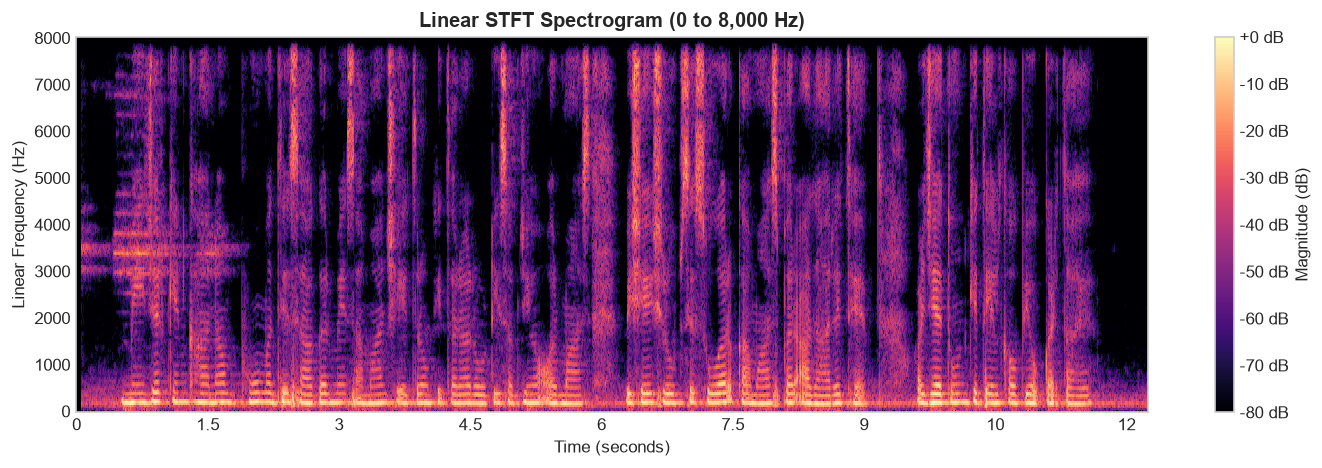

In [5]:
# Compute the Short-Time Fourier Transform (STFT)
n_fft = 400       # 25 ms analysis window at 16 kHz
hop_length = 160  # 10 ms hop between frames at 16 kHz

# Complex spectrogram D
D = librosa.stft(audio_array, n_fft=n_fft, hop_length=hop_length, window="hann")

# Convert complex numbers to magnitude (energy) and then to decibels (log scale)
magnitude = np.abs(D)
spectrogram_db = librosa.amplitude_to_db(magnitude, ref=np.max)

print(f"STFT Matrix Shape: {spectrogram_db.shape}")
print(f" - Frequency Bins (rows): {spectrogram_db.shape[0]} (from 0 Hz to {sample_rate//2} Hz)")
print(f" - Time Frames (cols):   {spectrogram_db.shape[1]} frames ({spectrogram_db.shape[1]/100:.2f} seconds)")

# Plot the Linear Spectrogram
fig, ax = plt.subplots(figsize=(12, 4))
img = librosa.display.specshow(
    spectrogram_db,
    sr=sample_rate,
    hop_length=hop_length,
    x_axis="time",
    y_axis="linear",
    ax=ax,
    cmap="magma"
)
fig.colorbar(img, ax=ax, format="%+2.0f dB", label="Magnitude (dB)")
ax.set_title("Linear STFT Spectrogram (0 to 8,000 Hz)", fontsize=12, fontweight="bold")
ax.set_xlabel("Time (seconds)")
ax.set_ylabel("Linear Frequency (Hz)")
plt.tight_layout()
plt.show()


### 6. The Mel Scale: Modeling Human Auditory Perception

#### The Limitation of Linear Frequency
Notice in the linear spectrogram above that the high frequencies (4,000 Hz to 8,000 Hz) occupy half of the vertical space. However, human ears do not hear frequencies linearly:
- Humans can easily tell the difference between **100 Hz and 200 Hz** (a musical octave).
- Humans can barely tell the difference between **7,000 Hz and 7,100 Hz**, even though the arithmetic difference (100 Hz) is identical!

The human cochlea resolves lower frequencies with much higher resolution than higher frequencies.

#### The Mel Formula
The **Mel scale** maps physical frequency in Hertz ($f$) to perceived pitch ($m$):
$$m = 2595 \cdot \log_{10}\left(1 + \frac{f}{700}\right)$$

- Below 1,000 Hz, the Mel scale is approximately linear.
- Above 1,000 Hz, the Mel scale becomes logarithmic.

#### Mel Filterbanks
To convert an STFT into a Mel-spectrogram, we multiply the linear frequency spectrum by a bank of triangular overlapping filters spaced linearly on the Mel scale.
Whisper uses **80 Mel filters** (`n_mels=80`), compressing 201 linear frequency bins into 80 perceptually relevant bands.


Mel Filterbank Matrix Shape: (80, 201)
 - Number of Mel bands:  80
 - Linear FFT bins:      201


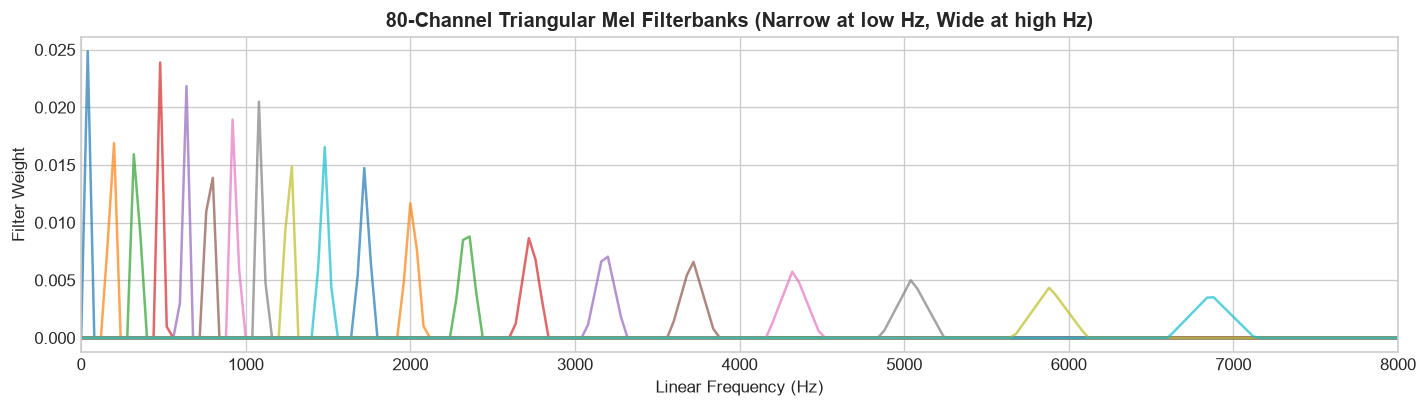

In [6]:
# Construct 80 Mel filterbanks spanning 0 Hz to 8,000 Hz
mel_filters = librosa.filters.mel(sr=sample_rate, n_fft=n_fft, n_mels=80, fmin=0.0, fmax=8000.0)

print(f"Mel Filterbank Matrix Shape: {mel_filters.shape}")
print(f" - Number of Mel bands:  {mel_filters.shape[0]}")
print(f" - Linear FFT bins:      {mel_filters.shape[1]}")

# Visualize the triangular Mel filterbanks
fig, ax = plt.subplots(figsize=(12, 3.5))
for i in range(0, 80, 4):  # Plot every 4th filter for visual clarity
    ax.plot(np.linspace(0, sample_rate // 2, mel_filters.shape[1]), mel_filters[i], alpha=0.7)
ax.set_title("80-Channel Triangular Mel Filterbanks (Narrow at low Hz, Wide at high Hz)", fontsize=12, fontweight="bold")
ax.set_xlabel("Linear Frequency (Hz)")
ax.set_ylabel("Filter Weight")
ax.set_xlim(0, 8000)
plt.tight_layout()
plt.show()


### 7. The 80-Channel Log-Mel Spectrogram: Whisper's Input Feature

We now compute the 80-channel Log-Mel spectrogram using `librosa.feature.melspectrogram`:
1. Compute the power spectrogram ($|\text{STFT}|^2$).
2. Multiply by the 80 Mel filterbank matrix.
3. Convert power to decibels using `librosa.power_to_db` (logarithmic dynamic range compression, mimicking human loudness perception).

This exact 80-channel 2D matrix is what passes into **Whisper's 1D convolutional audio encoder**!


Log-Mel Spectrogram Shape: (80, 1225)
 - 80 Mel Frequency Channels (Rows)
 - 1225 Time Frames (Columns)


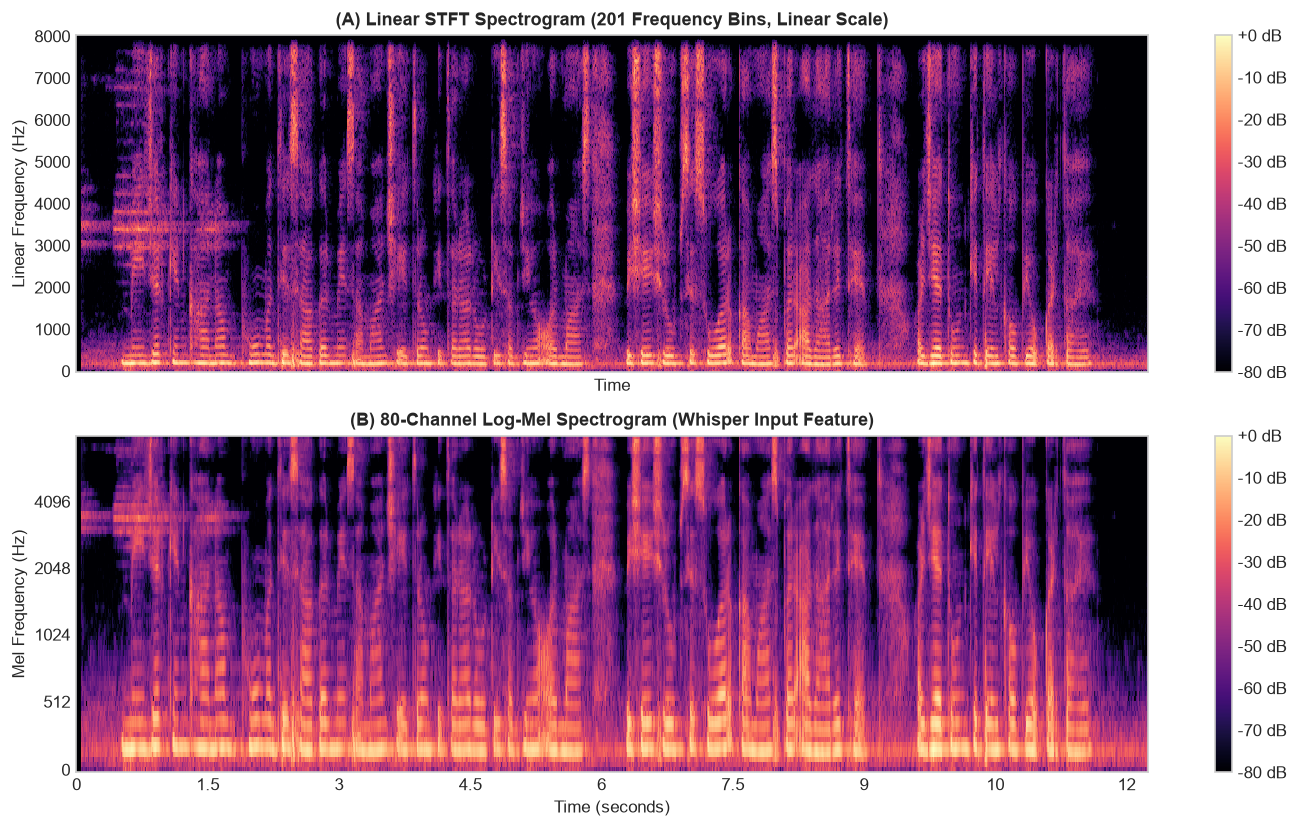

In [7]:
# 1. Compute Mel Spectrogram
mel_spec = librosa.feature.melspectrogram(
    y=audio_array,
    sr=sample_rate,
    n_fft=n_fft,
    hop_length=hop_length,
    n_mels=80,
    fmin=0.0,
    fmax=8000.0,
    power=2.0
)

# 2. Convert power to Decibels (Log-Mel)
log_mel_spec = librosa.power_to_db(mel_spec, ref=np.max)

print(f"Log-Mel Spectrogram Shape: {log_mel_spec.shape}")
print(f" - 80 Mel Frequency Channels (Rows)")
print(f" - {log_mel_spec.shape[1]} Time Frames (Columns)")

# Plot side-by-side comparison: Linear STFT vs 80-Channel Log-Mel Spectrogram
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

# Plot Linear STFT
img1 = librosa.display.specshow(
    spectrogram_db,
    sr=sample_rate,
    hop_length=hop_length,
    x_axis="time",
    y_axis="linear",
    ax=ax1,
    cmap="magma"
)
ax1.set_title("(A) Linear STFT Spectrogram (201 Frequency Bins, Linear Scale)", fontsize=11, fontweight="bold")
ax1.set_ylabel("Linear Frequency (Hz)")
fig.colorbar(img1, ax=ax1, format="%+2.0f dB")

# Plot 80-channel Log-Mel Spectrogram
img2 = librosa.display.specshow(
    log_mel_spec,
    sr=sample_rate,
    hop_length=hop_length,
    x_axis="time",
    y_axis="mel",
    fmin=0.0,
    fmax=8000.0,
    ax=ax2,
    cmap="magma"
)
ax2.set_title("(B) 80-Channel Log-Mel Spectrogram (Whisper Input Feature)", fontsize=11, fontweight="bold")
ax2.set_xlabel("Time (seconds)")
ax2.set_ylabel("Mel Frequency (Hz)")
fig.colorbar(img2, ax=ax2, format="%+2.0f dB")

plt.tight_layout()
plt.show()


### 8. Comparing with HuggingFace `WhisperFeatureExtractor`

HuggingFace provides `WhisperFeatureExtractor.from_pretrained("openai/whisper-small")` which performs this exact transformation under the hood.
Let's verify that our manual Librosa calculation matches the tensor shape expected by Whisper!


In [8]:
from transformers import WhisperFeatureExtractor

# Initialize Whisper's official feature extractor
feature_extractor = WhisperFeatureExtractor.from_pretrained("openai/whisper-small")

# Extract features (Whisper pads or truncates to 3,000 frames / 30 seconds by default)
inputs = feature_extractor(audio_array, sampling_rate=sample_rate, return_tensors="pt")
whisper_features = inputs.input_features

print("=== WhisperFeatureExtractor Output ===")
print(f"Tensor shape:              {whisper_features.shape}")
print(f" - Batch size:             {whisper_features.shape[0]}")
print(f" - Mel frequency bins:     {whisper_features.shape[1]} (80 channels)")
print(f" - Time frames (padded):   {whisper_features.shape[2]} frames (30.0 seconds at 100 fps)")
print(f"Min / Max values in tensor: {whisper_features.min().item():.3f} / {whisper_features.max().item():.3f}")


=== WhisperFeatureExtractor Output ===
Tensor shape:              torch.Size([1, 80, 3000])
 - Batch size:             1
 - Mel frequency bins:     80 (80 channels)
 - Time frames (padded):   3000 frames (30.0 seconds at 100 fps)
Min / Max values in tensor: -1.083 / 0.917


C:\Users\dkhan\Desktop\IIIT Hyderabad Speech Processing Lab\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\dkhan\.cache\huggingface\hub\models--openai--whisper-small. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


### 9. Summary & Key Interview Takeaways

| Concept | What It Is | Why It Matters for Whisper / Speech AI |
|:---|:---|:---|
| **Sampling Rate ($f_s$)** | Number of audio snapshots recorded per second. | Whisper requires **16,000 Hz**. Any input must be resampled to 16 kHz. |
| **Nyquist Frequency** | $f_s / 2$ (the maximum theoretical frequency captured). | At 16 kHz, Nyquist is **8 kHz**, which fully encompasses human vowel formants and consonant fricatives. |
| **Windowing (Hann)** | Multiplying a 25 ms frame by a smooth tapering bell curve. | Eliminates sharp edge discontinuities that cause false spectral leakage in the FFT. |
| **STFT** | Short-Time Fourier Transform: computes frequency spectrum over time frames. | Converts 1D time-domain sound into a 2D time-frequency matrix. |
| **Mel Scale** | Non-linear frequency scale: $m = 2595 \log_{10}(1 + f/700)$. | Models human cochlear perception (high resolution at low pitches, lower resolution at high pitches). |
| **Log-Mel Spectrogram** | 80 triangular Mel filterbanks applied to $|\text{STFT}|^2$, compressed with $\log$. | **The exact input fed into Whisper's transformer encoder.** |
